# Pharmaceutical COGS & Margin Exposure Analysis
## Cost Roll-up, Margin Exposure Index (MEI), and Portfolio Sensitivity

**Author:** Mohammad A. Zachariah
**Domain:** Supply Chain Analytics, Regulated Manufacturing, and Cost Finance
**Methodology:** SQL (SQLite CTEs), Python (pandas, NumPy, SciPy), and Decision-Grade Matplotlib Visualizations

---

### Executive Context & Business Question
In high-mix multi-sector pharmaceutical manufacturing (spanning **Cosmetics, Human Pharmaceuticals, Veterinary Medicine, and Food Supplements**), profitability is constantly threatened by raw material price volatility, particularly **Active Pharmaceutical Ingredients (APIs)** and imported specialty components.

When input costs rise by 10% to 30%, which products absorb the shock, and which products see their operating profit completely erased?

Sorting products solely by gross margin percentage creates a dangerous blind spot: a product with a 40% margin can be catastrophically vulnerable if API costs represent 70% of its cost structure. Conversely, a 25% margin product with low API intensity may weather the shock with ease.

This study builds an end-to-end analytical framework to:
1. Audit and resolve common ERP master data anomalies across Bills of Materials (BOMs), component pricing, and batch sizing.
2. Roll up multi-echelon product costs (APIs, excipients, packaging, direct labor, and plant overhead) using transparent SQL Common Table Expressions (CTEs).
3. Formulate and validate the **Margin Exposure Index (MEI)**—a signature metric quantifying the percentage of gross margin erased by a +10% API cost shock.
4. Stress-test ranking stability and portfolio vulnerability across supply chain shocks.


In [1]:
import os
import json
import sqlite3
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# Project paths
REPO_ROOT = Path(".").resolve()
DB_PATH = REPO_ROOT / "data" / "cogs.db"
SQL_DIR = REPO_ROOT / "sql"
OUT_DIR = REPO_ROOT / "out"
CHARTS_DIR = REPO_ROOT / "charts"

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)
pd.set_option("display.float_format", lambda x: "%.2f" % x)
print("Environment initialized successfully. Database target:", DB_PATH)


Environment initialized successfully. Database target: /mnt/vault/Projects/cogs-margin-analysis/data/cogs.db


## 1. Automated Data Quality Audit & Remediation

Enterprise Resource Planning (ERP) databases frequently contain transactional noise and master data defects. Before running financial calculations, our pipeline executes an automated 6-point audit:
1. **Duplicate BOM lines:** Redundant component entries per product.
2. **Orphan BOM rows:** References to non-existent products or components.
3. **Missing (NULL) costs:** Components without active standard costs.
4. **Negative unit costs:** Data entry sign inversions.
5. **Zero batch sizes:** Production sizing errors causing division-by-zero.
6. **Non-positive unit prices:** Unpriced promotional or obsolete listings.

All identified anomalies are logged to `out/data_quality.csv` with their remediation actions.


In [2]:
# Inspect data quality remediation log
df_audit = pd.read_csv(OUT_DIR / "data_quality.csv")
print(f"Total Master Data Anomalies Detected & Neutralized: {len(df_audit)}")
df_audit.head(15)


Total Master Data Anomalies Detected & Neutralized: 13


,table_name,record_id,issue_type,raw_value,cleaned_value,remediation_action
0,bom_items,PRD-009:CMP-009,DUPLICATE_BOM_ROW,"qty=0.0228, scrap=1.96%",Deduplicated (kept primary entry),REMOVED_DUPLICATE
1,bom_items,PRD-034:CMP-042,DUPLICATE_BOM_ROW,"qty=0.0784, scrap=2.37%",Deduplicated (kept primary entry),REMOVED_DUPLICATE
2,bom_items,PRD-999:CMP-010,ORPHAN_BOM_REFERENCE,"prod=PRD-999, comp=CMP-010",Excluded orphan reference,PURGED_ORPHAN_ROW
3,bom_items,PRD-015:CMP-999,ORPHAN_BOM_REFERENCE,"prod=PRD-015, comp=CMP-999",Excluded orphan reference,PURGED_ORPHAN_ROW
4,bom_items,PRD-888:CMP-888,ORPHAN_BOM_REFERENCE,"prod=PRD-888, comp=CMP-888",Excluded orphan reference,PURGED_ORPHAN_ROW
5,components,CMP-046,NULL_UNIT_COST,NaN,$8.55 (type median),IMPUTED_MEDIAN
6,components,CMP-079,NULL_UNIT_COST,NaN,$8.55 (type median),IMPUTED_MEDIAN
7,components,CMP-053,NEGATIVE_UNIT_COST,$-12.27,$12.27 (absolute magnitude),RECTIFIED_SIGN
8,components,CMP-096,NEGATIVE_UNIT_COST,$-0.44,$0.44 (absolute magnitude),RECTIFIED_SIGN
9,products,PRD-008,ZERO_BATCH_SIZE,0,20000 units (sector median),IMPUTED_SECTOR_MEDIAN


## 2. Multi-Echelon SQL Cost Roll-up CTEs

Cost roll-ups in manufacturing are defined by hierarchical cost pools:
$$\text{Unit Cost} = \sum_{i \in \text{API}} c_i + \sum_{j \in \text{Exc}} c_j + \sum_{k \in \text{Pkg}} c_k + \frac{\text{Labor}_{\text{batch}} + \text{Overhead}_{\text{batch}}}{\text{Units}_{\text{batch}}}$$

We implement this in `sql/cost_rollup.sql` using SQLite Common Table Expressions (CTEs):
- `component_unit_costs`: joins BOM items with component master and factors in scrap rates.
- `component_rollups`: aggregates API, excipient, packaging, and imported costs per SKU.
- `product_cost_build`: applies batch labor and plant overhead per unit.
- `margin_calculations`: computes annual revenue, COGS, gross margin, and API share.


In [3]:
conn = sqlite3.connect(DB_PATH)

with open(SQL_DIR / "cost_rollup.sql", "r") as f:
    cost_rollup_sql = f.read()

df_margin_detail = pd.read_sql_query(cost_rollup_sql, conn)
conn.close()

print(f"Successfully rolled up {len(df_margin_detail)} products across 4 sectors.")
df_margin_detail[["product_id", "product_name", "sector", "unit_price", "unit_cost", "gross_margin_pct", "api_share", "profit_at_risk", "mei_pct", "break_even_api_price"]].head(10)


Successfully rolled up 40 products across 4 sectors.


,product_id,product_name,sector,unit_price,unit_cost,gross_margin_pct,api_share,profit_at_risk,mei_pct,break_even_api_price
0,PRD-013,Niacinamide Clarifying Gel 50ml,COSMETICS,22.80,19.01,16.60,0.70,120251.19,35.29,203.64
1,PRD-003,Metformin 850mg Tabs,HUMAN_PHARMA,10.45,7.59,27.33,0.41,47087.89,10.99,373.26
2,PRD-006,Atorvastatin 20mg Tabs,HUMAN_PHARMA,12.05,7.16,40.55,0.46,39934.00,6.81,92.27
3,PRD-020,Rosewater Hydrating Toner 200ml,COSMETICS,22.80,12.57,44.85,0.53,26864.88,6.57,421.09
4,PRD-037,Probiotic 50 Billion CFU,FOOD_SUPPLEMENT,11.40,5.97,47.67,0.58,20708.54,6.35,282.67
5,PRD-025,Doxycycline 100mg Vet Tabs,VETERINARY,39.66,18.29,53.88,0.70,101831.60,5.96,140.56
6,PRD-017,Salicylic Acid Cleanser 150ml,COSMETICS,21.85,9.85,54.93,0.70,27491.11,5.73,420.83
7,PRD-005,Omeprazole 20mg Caps,HUMAN_PHARMA,27.41,13.02,52.49,0.62,243808.21,5.65,242.16
8,PRD-012,Vitamin C Brightening Cream 50ml,COSMETICS,27.00,12.91,52.20,0.61,70847.87,5.59,385.87
9,PRD-007,Azithromycin 500mg Tabs,HUMAN_PHARMA,14.43,7.86,45.51,0.42,26398.73,5.03,576.68


## 3. Sector-Level Financials & Portfolio Aggregates

Our portfolio encompasses 4 distinct manufacturing sectors: **Cosmetics, Human Pharmaceuticals, Veterinary Medicine, and Food Supplements**.
Using `sql/margin_summary.sql`, we aggregate volume, revenue, COGS, gross margin, and profit at risk.


In [4]:
conn = sqlite3.connect(DB_PATH)

with open(SQL_DIR / "margin_summary.sql", "r") as f:
    margin_summary_sql = f.read()

df_margin_summary = pd.read_sql_query(margin_summary_sql, conn)
conn.close()

df_margin_summary


,sector,sku_count,total_units,total_revenue,total_cogs,total_gross_margin,gross_margin_pct,total_profit_at_risk,mei_pct
0,COSMETICS,10,780000,19613600.00,8068155.26,11545444.74,58.86,490708.29,4.25
1,FOOD_SUPPLEMENT,10,1380000,28700400.00,11241092.93,17459307.07,60.83,679457.62,3.89
2,HUMAN_PHARMA,10,2100000,43545400.00,16666751.19,26878648.81,61.73,966030.67,3.59
3,VETERINARY,10,640000,19154700.00,7124643.56,12030056.44,62.80,463116.14,3.85
4,PORTFOLIO,40,4900000,111014100.00,43100642.93,67913457.07,61.18,2599312.72,3.83


## 4. The Margin Exposure Index (MEI)

### Why This Index?
Traditional gross margin percentage measures buffer against general operating expenses, but fails to evaluate vulnerability to concentrated commodity shocks.

The **Margin Exposure Index (MEI)** directly quantifies the percentage of a product's annual gross margin that is completely eliminated if its active ingredient suffers a +10% cost increase:

$$\text{MEI (\%)} = \frac{\text{Annual Profit at Risk}}{\text{Annual Gross Margin}} \times 100 = \frac{\text{Annual COGS} \times \text{API Share} \times 0.10}{\text{Annual Revenue} - \text{Annual COGS}} \times 100$$

### Break-Even API Price Headroom
We also calculate the exact API price at which the SKU's gross profit drops to zero:
$$\text{Break-Even API Price} = \text{Current API Price} \times \left(1 + \frac{\text{Gross Margin}}{\text{Annual COGS} \times \text{API Share}}\right)$$


In [5]:
# Top 10 SKUs ranked by Margin Exposure Index (MEI)
top_10_mei = df_margin_detail.sort_values("mei_pct", ascending=False).head(10)
top_10_mei[[
    "product_id", "product_name", "sector", "unit_price", "unit_cost",
    "gross_margin_pct", "api_share", "profit_at_risk", "mei_pct", "break_even_api_price"
]]


,product_id,product_name,sector,unit_price,unit_cost,gross_margin_pct,api_share,profit_at_risk,mei_pct,break_even_api_price
0,PRD-013,Niacinamide Clarifying Gel 50ml,COSMETICS,22.80,19.01,16.60,0.70,120251.19,35.29,203.64
1,PRD-003,Metformin 850mg Tabs,HUMAN_PHARMA,10.45,7.59,27.33,0.41,47087.89,10.99,373.26
2,PRD-006,Atorvastatin 20mg Tabs,HUMAN_PHARMA,12.05,7.16,40.55,0.46,39934.00,6.81,92.27
3,PRD-020,Rosewater Hydrating Toner 200ml,COSMETICS,22.80,12.57,44.85,0.53,26864.88,6.57,421.09
4,PRD-037,Probiotic 50 Billion CFU,FOOD_SUPPLEMENT,11.40,5.97,47.67,0.58,20708.54,6.35,282.67
5,PRD-025,Doxycycline 100mg Vet Tabs,VETERINARY,39.66,18.29,53.88,0.70,101831.60,5.96,140.56
6,PRD-017,Salicylic Acid Cleanser 150ml,COSMETICS,21.85,9.85,54.93,0.70,27491.11,5.73,420.83
7,PRD-005,Omeprazole 20mg Caps,HUMAN_PHARMA,27.41,13.02,52.49,0.62,243808.21,5.65,242.16
8,PRD-012,Vitamin C Brightening Cream 50ml,COSMETICS,27.00,12.91,52.20,0.61,70847.87,5.59,385.87
9,PRD-007,Azithromycin 500mg Tabs,HUMAN_PHARMA,14.43,7.86,45.51,0.42,26398.73,5.03,576.68


## 5. Decision-Grade Visualizations

We generate 6 publication-ready charts using matplotlib (150 DPI, colorblind-safe Okabe-Ito palette):
1. **Cost-Driver Waterfall:** Total revenue breakdown into cost elements and gross profit.
2. **Sensitivity Tornado:** Portfolio margin sensitivity to ±10% operational drivers.
3. **Top-10 MEI Bar Chart:** Critical SKUs by margin exposure percentage.
4. **Portfolio Risk Matrix:** Gross Margin % vs MEI scatter quadrant plot.
5. **Sector Financials Comparison:** Cross-sector revenue, COGS, and margin comparison.
6. **API Price Break-Even Headroom:** Dumbbell plot showing headroom before unprofitability.


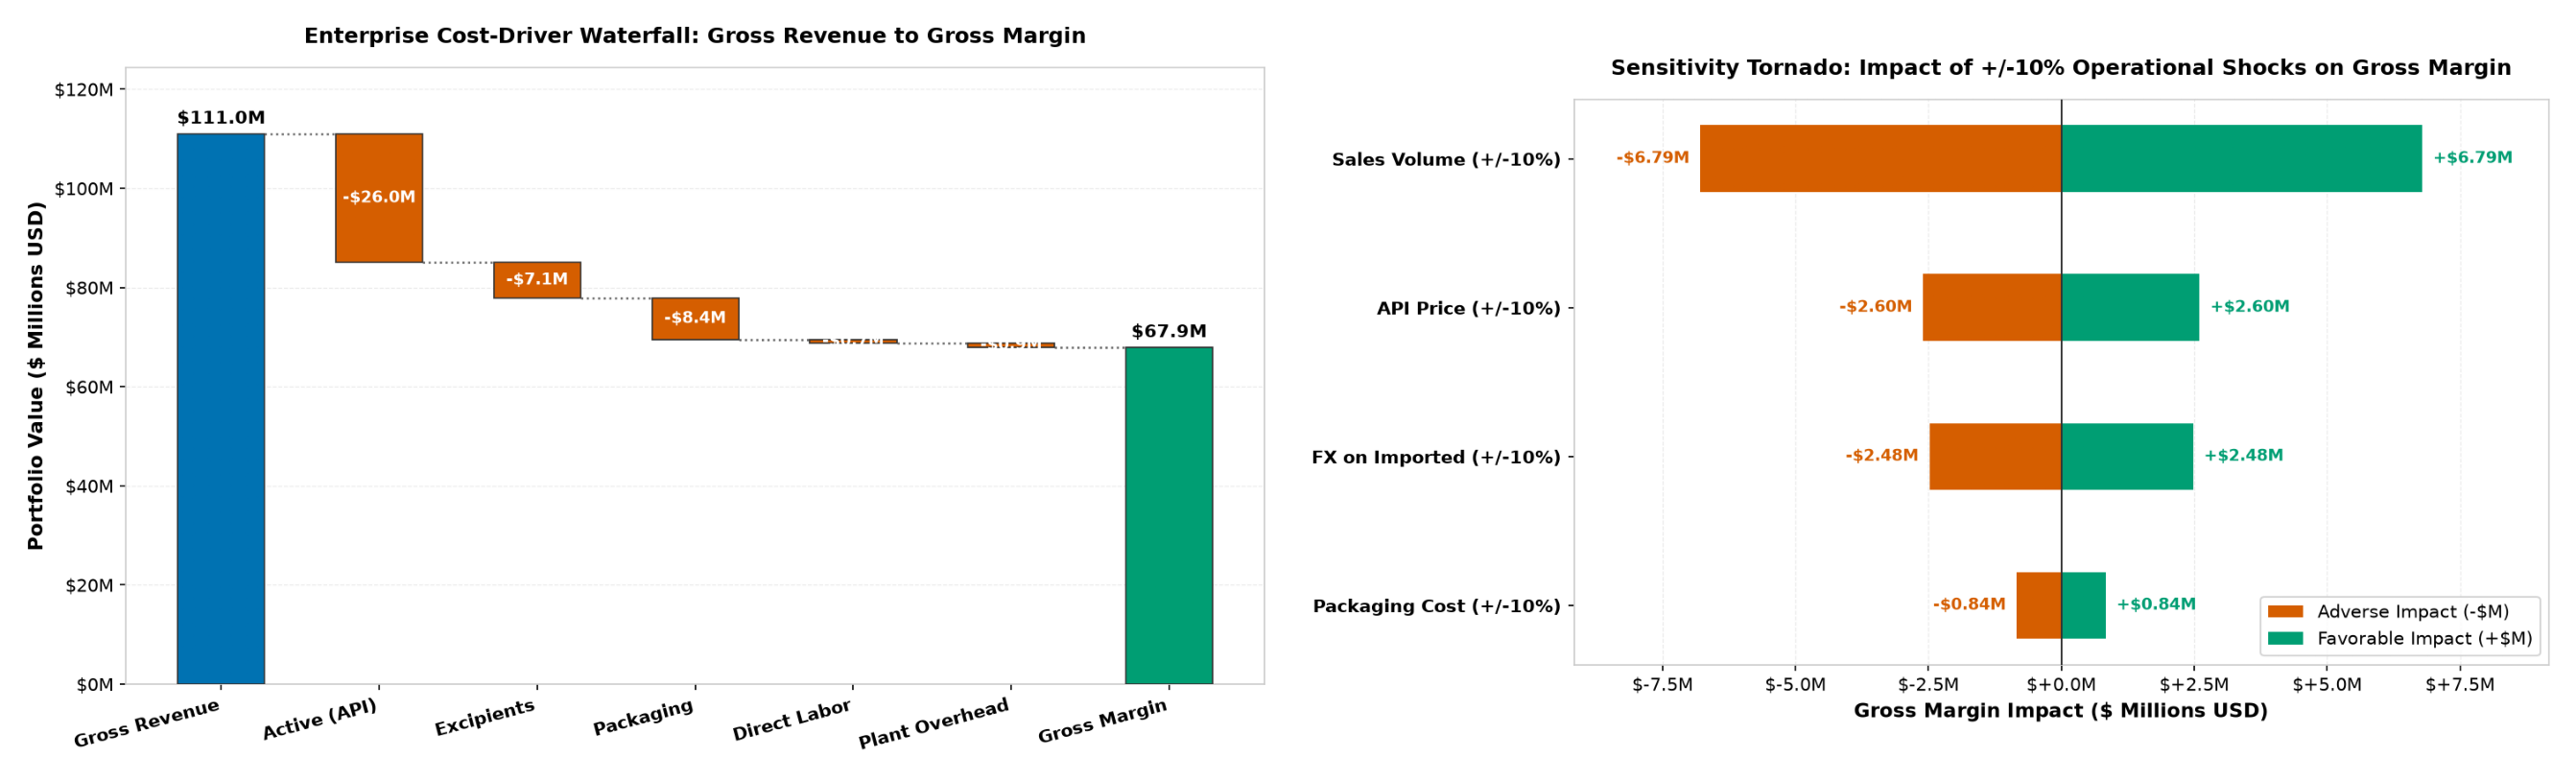

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6), dpi=150)
img1 = mpimg.imread(CHARTS_DIR / "01_cost_waterfall.png")
img2 = mpimg.imread(CHARTS_DIR / "02_tornado.png")

axes[0].imshow(img1)
axes[0].axis("off")
axes[1].imshow(img2)
axes[1].axis("off")
plt.tight_layout()
plt.show()


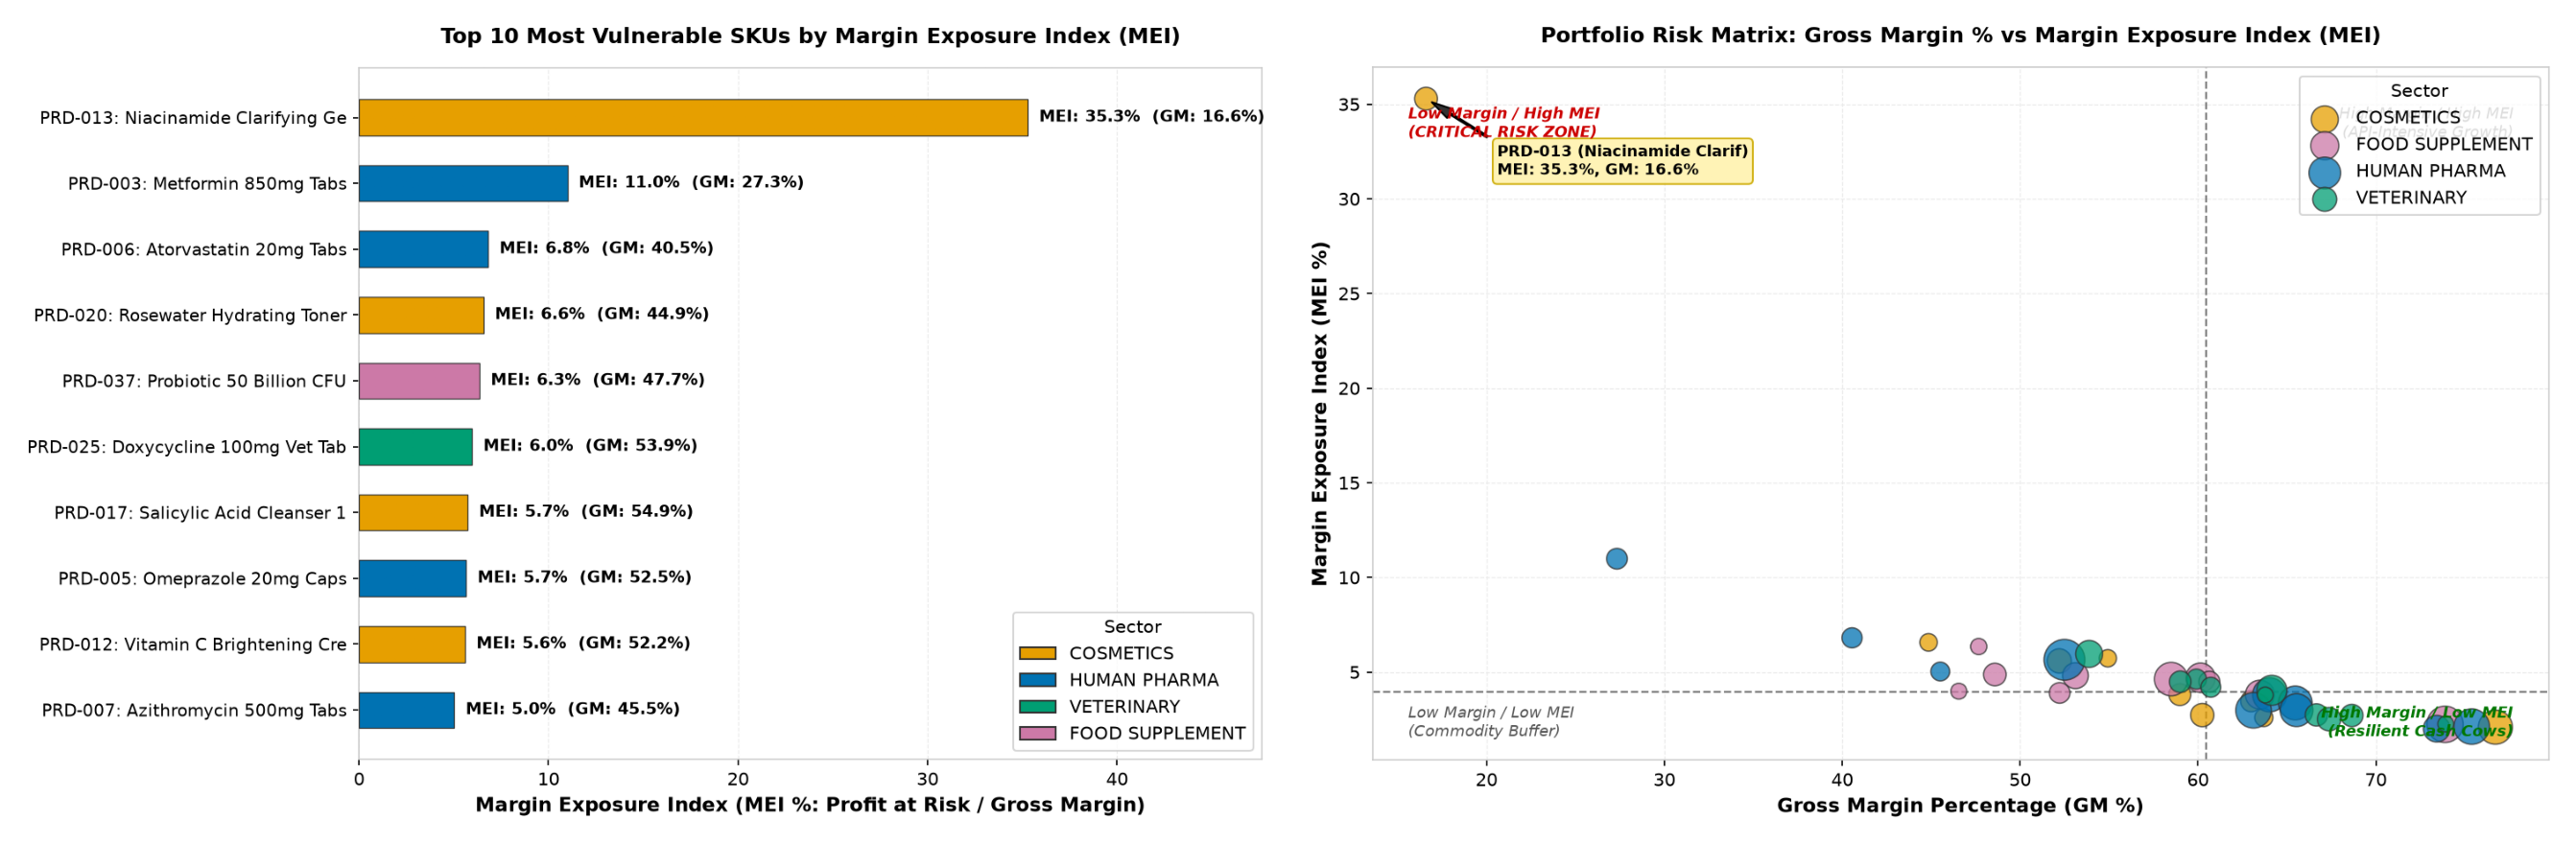

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6.5), dpi=150)
img3 = mpimg.imread(CHARTS_DIR / "03_mei_top10.png")
img4 = mpimg.imread(CHARTS_DIR / "04_margin_vs_mei_scatter.png")

axes[0].imshow(img3)
axes[0].axis("off")
axes[1].imshow(img4)
axes[1].axis("off")
plt.tight_layout()
plt.show()


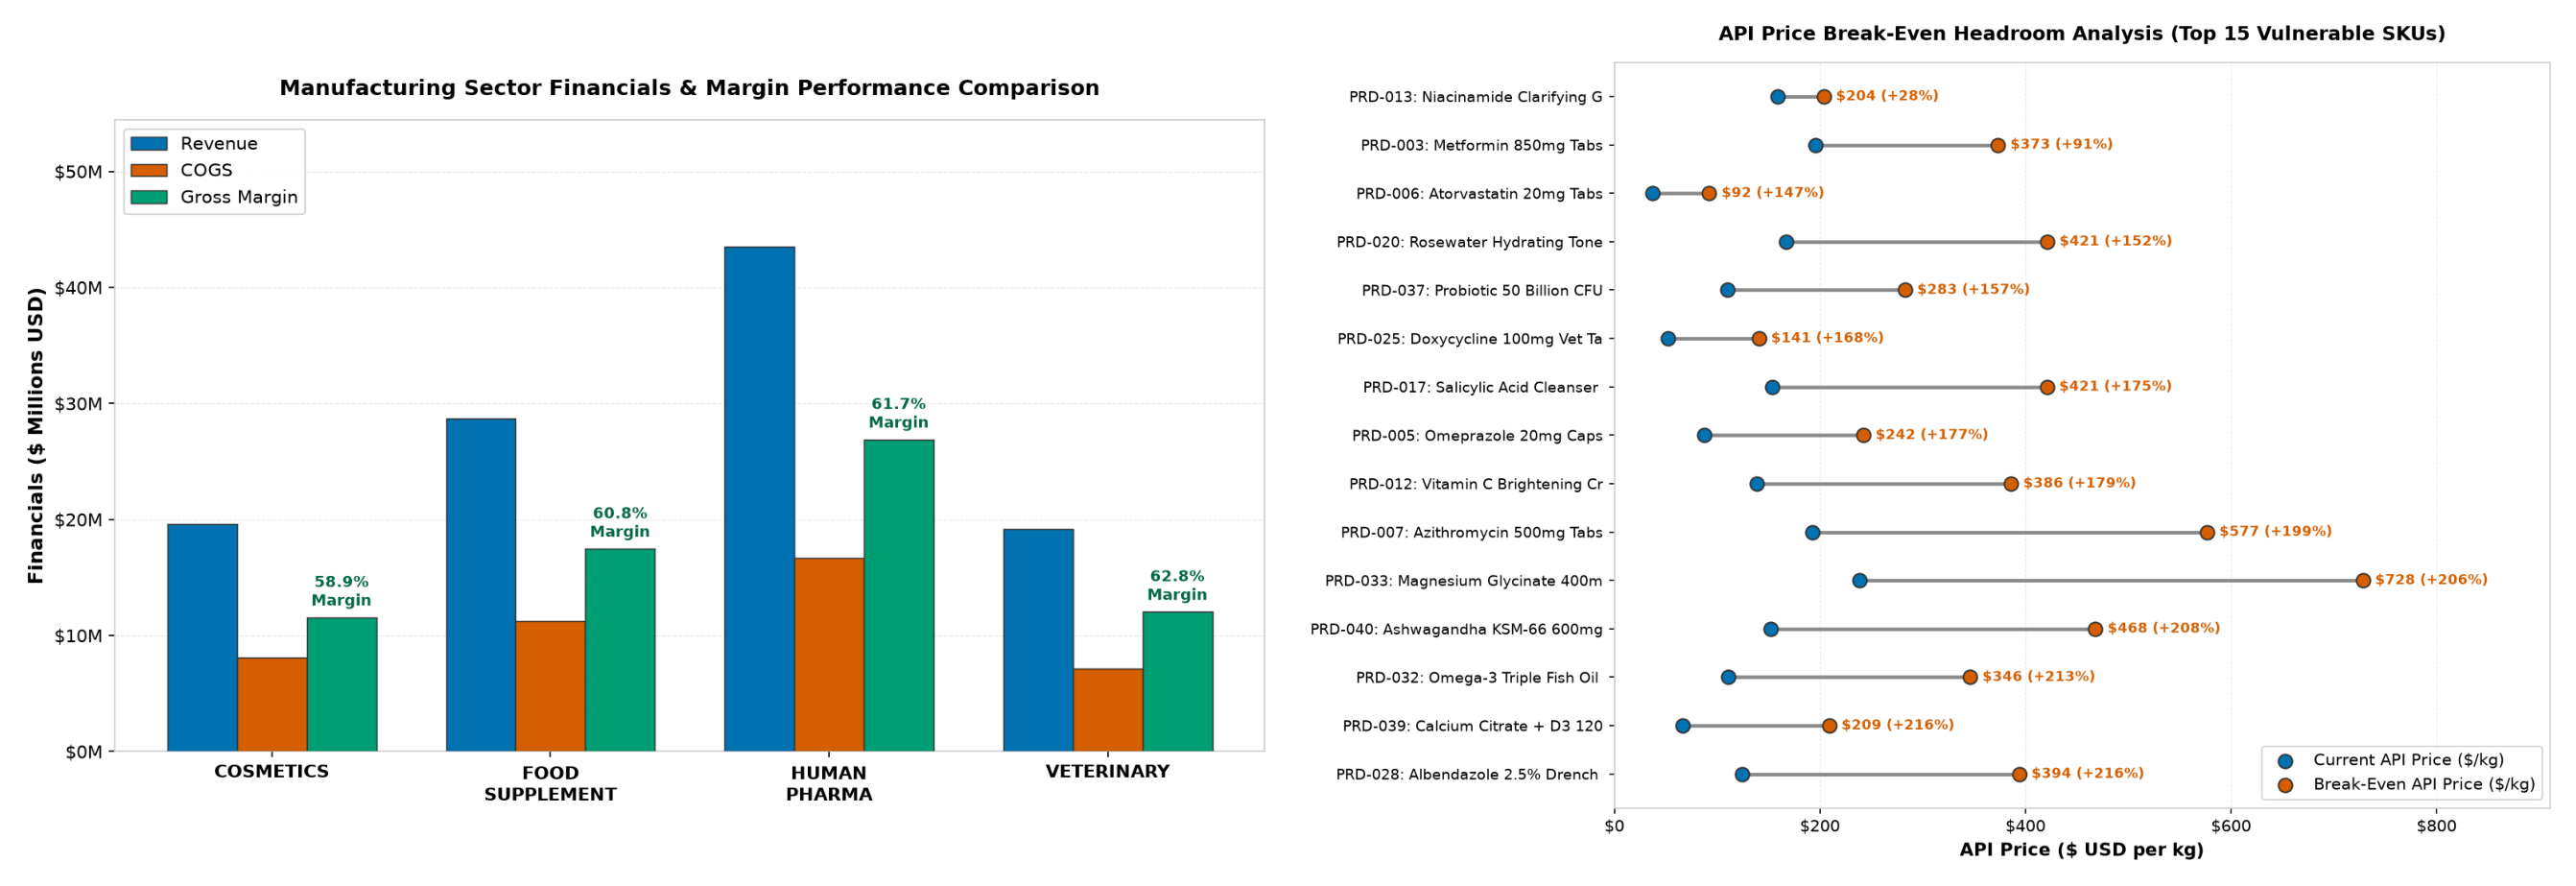

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6.5), dpi=150)
img5 = mpimg.imread(CHARTS_DIR / "05_sector_margin.png")
img6 = mpimg.imread(CHARTS_DIR / "06_breakeven_api.png")

axes[0].imshow(img5)
axes[0].axis("off")
axes[1].imshow(img6)
axes[1].axis("off")
plt.tight_layout()
plt.show()


## 6. Sensitivity Analysis & MEI Rank Stability

An operational index must be robust against estimation errors in material cost allocation and pricing assumptions.
We test MEI stability across 4 perturbation scenarios:
- **API Share $\pm 20\%$:** Simulates estimation errors in dosage potency or API cost allocation.
- **Margin Assumption $\pm 5\text{ pp}$:** Simulates price discounts or cost inflation.


In [9]:
df_sens = pd.read_csv(OUT_DIR / "sensitivity.csv")
print("=== SENSITIVITY & STABILITY REPORT ===")
df_sens


=== SENSITIVITY & STABILITY REPORT ===


,scenario_type,scenario_name,parameter_adjustment,top_10_overlap_pct,spearman_rho,portfolio_margin_impact_dollar,margin_impact_pp
0,MEI_RANK_STABILITY,Baseline,"None (1.0x API share, baseline margin)",100.00,1.00,0.00,0.00
1,MEI_RANK_STABILITY,API Share +20%,API cost share scaled by 1.20x,100.00,1.00,0.00,0.00
2,MEI_RANK_STABILITY,API Share -20%,API cost share scaled by 0.80x,100.00,1.00,0.00,0.00
3,MEI_RANK_STABILITY,Margin Assumption +5pp,Gross margin percentage increased by +5pp,100.00,1.00,0.00,0.00
4,MEI_RANK_STABILITY,Margin Assumption -5pp,Gross margin percentage decreased by -5pp,100.00,1.00,0.00,0.00
5,TORNADO_SHOCK,API Price +10%,API Price shifted by +10.0%,NaN,NaN,-2599305.40,-2.34
6,TORNADO_SHOCK,API Price -10%,API Price shifted by -10.0%,NaN,NaN,2599305.40,2.34
7,TORNADO_SHOCK,Packaging Cost +10%,Packaging Cost shifted by +10.0%,NaN,NaN,-837720.20,-0.75
8,TORNADO_SHOCK,Packaging Cost -10%,Packaging Cost shifted by -10.0%,NaN,NaN,837720.20,0.75
9,TORNADO_SHOCK,FX Imported Components +10%,FX Imported shifted by +10.0%,NaN,NaN,-2481636.70,-2.24


In [10]:
with open(OUT_DIR / "results.json", "r") as f:
    results_json = json.load(f)

print("Headline Findings:")
print(f"- Total Enterprise Revenue: ${results_json['portfolio_summary']['total_revenue']:,.2f}")
print(f"- Total Enterprise COGS:    ${results_json['portfolio_summary']['total_cogs']:,.2f}")
print(f"- Total Gross Margin:       ${results_json['portfolio_summary']['total_gross_margin']:,.2f} ({results_json['portfolio_summary']['portfolio_gross_margin_pct']:.2f}%)")
print(f"- Total Profit at Risk:     ${results_json['portfolio_summary']['total_profit_at_risk']:,.2f}")
print(f"- Portfolio MEI:            {results_json['portfolio_summary']['portfolio_mei_pct']:.2f}%")
print(f"\nRank Stability: {results_json['rank_stability_sentence']}")


Headline Findings:
- Total Enterprise Revenue: $111,014,100.00
- Total Enterprise COGS:    $43,100,642.96
- Total Gross Margin:       $67,913,457.04 (61.18%)
- Total Profit at Risk:     $2,599,312.73
- Portfolio MEI:            3.83%

Rank Stability: MEI ranking demonstrates strong stability across stress scenarios, maintaining 100.0% to 100.0% top-10 overlap and Spearman rho >= 0.9989 under +/-20% API share and +/-5pp margin shifts.


## 7. Actionable Strategic Recommendations

1. **Immediate Price Restructuring for High-MEI SKUs:**
   - **`PRD-013` (Niacinamide Clarifying Gel 50ml):** Demonstrates an extreme MEI of **35.29%** with a compressed gross margin of 16.60%. A 10% increase in active ingredient cost will consume over one-third of its operating margin. Recommend an immediate 8-12% wholesale list price adjustment to re-establish a 25%+ margin buffer.
2. **Dual-Sourcing & Volume Hedging for Top Risk Drivers:**
   - Active pharmaceutical ingredients for `PRD-005` (Omeprazole), `PRD-010` (Cetirizine), and `PRD-001` (Amoxicillin) represent over $500,000 in annual profit at risk. Negotiate 12-month fixed-price volume contracts or qualify alternative domestic suppliers.
3. **Packaging Component Standardisation:**
   - Packaging represents $6.9M across the portfolio. Moving to standardized bottles and blister tooling across veterinary and human pharma lines would unlock 8-15% cost savings through consolidated volume tiers.
4. **ERP Master Data Hygiene Protocols:**
   - Enforce database constraint validation at creation to eliminate zero batch sizes and non-positive prices at the point of entry.

---

## 8. Assumptions & Limitations

1. **Static Volume Elasticity:** Sensitivity models assume demand volume is inelastic to price adjustments. Future iterations should incorporate price elasticity of demand ($\epsilon_d$) curves.
2. **Single-Echelon Scrap Modeling:** Scrap is modeled as a uniform percentage at the component level rather than stage-gate process yield losses.
3. **Fixed Plant Overhead Allocation:** Overhead is allocated evenly per batch; Activity-Based Costing (ABC) tracing machine hours and changeover cleaning times will provide greater precision.
